# TGAIN reproduction – German Credit (Table 5.2)

Modern-Python counterpart of the original `TGAIN_illustration.ipynb`. Runs one configuration (30 % missing, as in the original notebook) and then shows the aggregated results produced by `experiments/run_german.py`.

Works locally or in Google Colab (uncomment the first cell).

In [1]:
# --- Colab only ---
# !git clone https://github.com/<your-user>/tgain-reproduction.git
# %cd tgain-reproduction
# !pip install -q -r requirements.txt

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd())
ROOT = sys.path[0]
import numpy as np, pandas as pd
from sklearn.utils import shuffle
from tgain import data_imputation_completer, evaluate_imputations_original, evaluate_imputations_corrected

In [3]:
# 1. Rebuild the preprocessed German Credit data (999 rows, 432 complete)
!{sys.executable} {ROOT}/data/prepare_german.py
german = pd.read_csv(f'{ROOT}/data/german_data_preprocessed.csv', keep_default_na=False, na_values=[''])
german.head()

rows=999 cols=21 complete=432 incomplete=567
missingness pattern proportions (cf. thesis Fig. 5.1):
Status_existing_account  Month  Credit_history  Purpose  Credit_amount  Savings  Employment_since_years  Installment_rate_percentage  Gender_and_relationship_status  Other_debtors  Present_residence_since  Property  Age    Other_installment_plans  Housing  Number_existing_credits  Job    Number_people_liable  Telephone  Foreign_worker  Credit_risk
False                    False  False           False    False          False    False                   False                        False                           False          False                    False     False  False                    False    False                    False  False                 False      False           False          0.432
True                     False  False           False    False          False    False                   False                        False                           False          False     

,Status_existing_account,Month,Credit_history,Purpose,Credit_amount,Savings,Employment_since_years,Installment_rate_percentage,Gender_and_relationship_status,Other_debtors,...,Property,Age,Other_installment_plans,Housing,Number_existing_credits,Job,Number_people_liable,Telephone,Foreign_worker,Credit_risk
0,0<=x<200,48,credits_paid_till_now,radio/television,5951,x<100,1<=x<4,2,female_divorced,none,...,real_estate,22,none,own,1,skilled,1,none,yes,2
1,NaN,12,critical_account,education,2096,x<100,4<=x<7,2,male_single,none,...,real_estate,49,none,own,1,unskilled_resident,2,none,yes,1
2,x<0,42,credits_paid_till_now,furniture/equipment,7882,x<100,4<=x<7,2,male_single,guarantor,...,building_society_savings,45,none,for_free,1,skilled,2,none,yes,1
3,x<0,24,delay_in_earlier_payments,car_new,4870,x<100,1<=x<4,3,male_single,none,...,NaN,53,none,for_free,2,skilled,2,none,yes,2
4,NaN,36,credits_paid_till_now,education,9055,NaN,1<=x<4,2,male_single,none,...,NaN,35,none,for_free,1,unskilled_resident,2,yes,yes,1


In [4]:
# 2. Split exactly like the original notebook: 382 training rows, 50 test rows
complete = shuffle(german.dropna(), random_state=0)
test, train = complete[:50], complete[50:]
rate = 0.3
mask = np.random.RandomState(int(rate*100)*1000).random(test.shape) < rate
total = pd.concat([train, test.mask(mask)], ignore_index=True)

In [5]:
# 3. Impute (3 CTGAN models, 300 epochs; ~2-4 min on a laptop CPU)
completed, details = data_imputation_completer(total, nr_epochs=300, distinct_ratio_threshold=0.01,
    generator_lr=2e-4, discriminator_lr=2e-4, seed=0, return_details=True, preserve_order=True)
imputed_test = completed.tail(50).reset_index(drop=True)
print('TGAIN (3 models), original metric :', evaluate_imputations_original(train, test, mask, imputed_test, 0.01))
print('TGAIN (3 models), corrected metric:', evaluate_imputations_corrected(german, test, mask, imputed_test, 0.01))
m1 = details['per_model'][0].tail(50).reset_index(drop=True)
print('TGAIN (1 model),  original metric :', evaluate_imputations_original(train, test, mask, m1, 0.01))

TGAIN (3 models), original metric : 0.3142698206016573
TGAIN (3 models), corrected metric: 0.14684902936815136
TGAIN (1 model),  original metric : 0.34237761924400545


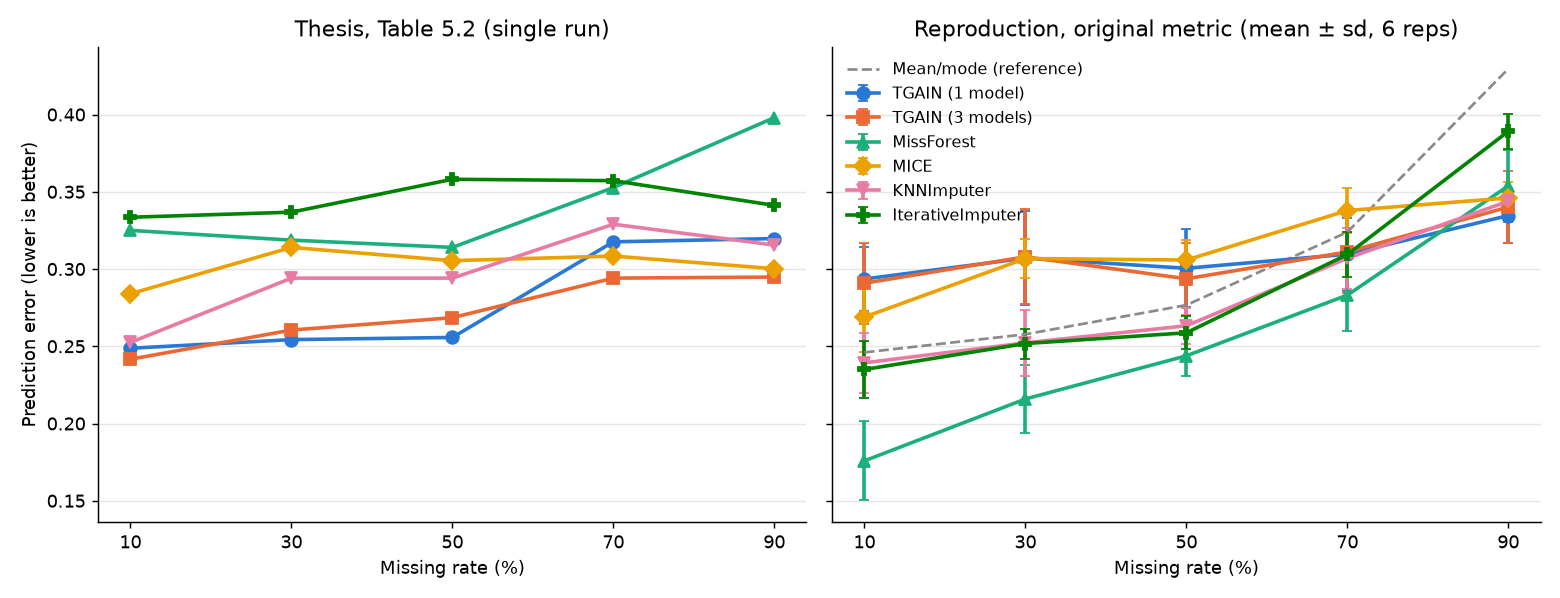

## Thesis Table 5.2

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| TGAIN (1 model) | 0.2487 | 0.2543 | 0.2557 | 0.3176 | 0.3197 |
| TGAIN (3 models) | 0.2416 | 0.2605 | 0.2685 | 0.2941 | 0.2948 |
| MissForest | 0.3250 | 0.3187 | 0.3140 | 0.3527 | 0.3980 |
| MICE | 0.2840 | 0.3140 | 0.3054 | 0.3084 | 0.3002 |
| KNNImputer | 0.2525 | 0.2941 | 0.2941 | 0.3290 | 0.3155 |
| IterativeImputer | 0.3335 | 0.3368 | 0.3581 | 0.3572 | 0.3412 |

## Reproduction - original metric (mean ± std over 6 repetitions)

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| TGAIN (1 model) | 0.2935 ± 0.0208 | 0.3071 ± 0.0302 | 0.3005 ± 0.0251 | 0.3096 ± 0.0237 | 0.3346 ± 0.0181 |
| TGAIN (3 models) | 0.2908 ± 0.0262 | 0.3079 ± 0.0309 | 0.2937 ± 0.0232 | 0.3111 ± 0.0264 | 0.3401 ± 0.0234 |
| MissForest | 0.1758 ± 0.0256 | 0.2159 ± 0.0223 | 0.2438 ± 0.0133 | 0.2831 ± 0.0231 | 0.3538 ± 0.0232 |
| MICE | 0.2689 ± 0.0228 | 0.3068 ± 0.0128 | 0.3058 ± 0.0127 | 0.3379 ± 0.0144 | 0.3460 ± 0.0105 |
| KNNImputer | 0.2393 ± 0.0194 | 0.2522 ± 0.0215 | 0.2633 ± 0.0118 | 0.3070 ± 0.0199 | 0.3439 ± 0.0073 |
| IterativeImputer | 0.2350 ± 0.0183 | 0.2517 ± 0.0097 | 0.2587 ± 0.0107 | 0.3094 ± 0.0145 | 0.3891 ± 0.0115 |
| MeanMode | 0.2460 ± 0.0294 | 0.2577 ± 0.0161 | 0.2767 ± 0.0142 | 0.3239 ± 0.0210 | 0.4296 ± 0.0193 |

## Reproduction - corrected metric

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| TGAIN (1 model) | 0.1455 ± 0.0129 | 0.1450 ± 0.0104 | 0.1425 ± 0.0076 | 0.1533 ± 0.0067 | 0.1564 ± 0.0052 |
| TGAIN (3 models) | 0.1397 ± 0.0173 | 0.1457 ± 0.0103 | 0.1362 ± 0.0086 | 0.1447 ± 0.0055 | 0.1472 ± 0.0038 |
| MissForest | 0.0877 ± 0.0093 | 0.0975 ± 0.0073 | 0.1069 ± 0.0097 | 0.1259 ± 0.0027 | 0.1377 ± 0.0040 |
| MICE | 0.1452 ± 0.0082 | 0.1568 ± 0.0073 | 0.1559 ± 0.0076 | 0.1694 ± 0.0049 | 0.1750 ± 0.0043 |
| KNNImputer | 0.1273 ± 0.0075 | 0.1302 ± 0.0102 | 0.1341 ± 0.0074 | 0.1498 ± 0.0033 | 0.1502 ± 0.0045 |
| IterativeImputer | 0.1315 ± 0.0091 | 0.1281 ± 0.0072 | 0.1298 ± 0.0066 | 0.1464 ± 0.0014 | 0.1486 ± 0.0010 |
| MeanMode | 0.1111 ± 0.0055 | 0.1108 ± 0.0028 | 0.1141 ± 0.0081 | 0.1332 ± 0.0029 | 0.1364 ± 0.0017 |

## Mean rank per missing rate (original metric)

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| TGAIN (1 model) | 5.5 (paper 2) | 5.2 (paper 1) | 5.2 (paper 1) | 3.3 (paper 3) | 2.0 (paper 4) |
| TGAIN (3 models) | 5.3 (paper 1) | 4.8 (paper 2) | 4.3 (paper 2) | 4.2 (paper 1) | 3.0 (paper 1) |
| MissForest | 1.0 (paper 5) | 1.0 (paper 5) | 1.2 (paper 5) | 1.0 (paper 5) | 3.8 (paper 6) |
| MICE | 3.8 (paper 4) | 5.0 (paper 4) | 5.2 (paper 4) | 5.3 (paper 2) | 3.3 (paper 2) |
| KNNImputer | 2.8 (paper 3) | 2.7 (paper 3) | 3.2 (paper 3) | 3.5 (paper 4) | 3.0 (paper 3) |
| IterativeImputer | 2.5 (paper 6) | 2.3 (paper 6) | 2.0 (paper 6) | 3.7 (paper 6) | 5.8 (paper 5) |

## Mean absolute error on numerical cells (shared [0,1] scale)

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| TGAIN (1 model) | 0.1819 ± 0.0245 | 0.1969 ± 0.0442 | 0.1803 ± 0.0205 | 0.1774 ± 0.0200 | 0.1813 ± 0.0318 |
| TGAIN (3 models) | 0.1819 ± 0.0245 | 0.1966 ± 0.0447 | 0.1791 ± 0.0201 | 0.1762 ± 0.0188 | 0.1826 ± 0.0323 |
| MissForest | 0.0987 ± 0.0165 | 0.0960 ± 0.0105 | 0.1008 ± 0.0104 | 0.1065 ± 0.0052 | 0.1141 ± 0.0039 |
| MICE | 0.1291 ± 0.0131 | 0.1356 ± 0.0185 | 0.1443 ± 0.0119 | 0.1478 ± 0.0141 | 0.1640 ± 0.0092 |
| KNNImputer | 0.1076 ± 0.0174 | 0.1069 ± 0.0134 | 0.1087 ± 0.0076 | 0.1115 ± 0.0073 | 0.1189 ± 0.0036 |
| IterativeImputer | 0.0892 ± 0.0196 | 0.0920 ± 0.0124 | 0.0937 ± 0.0075 | 0.1049 ± 0.0028 | 0.1113 ± 0.0033 |
| MeanMode | 0.1188 ± 0.0202 | 0.1109 ± 0.0070 | 0.1147 ± 0.0060 | 0.1148 ± 0.0029 | 0.1159 ± 0.0020 |

## Error rate on categorical cells

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| TGAIN (1 model) | 0.4750 ± 0.0588 | 0.4645 ± 0.0211 | 0.4639 ± 0.0243 | 0.5084 ± 0.0227 | 0.5189 ± 0.0161 |
| TGAIN (3 models) | 0.4522 ± 0.0773 | 0.4677 ± 0.0208 | 0.4395 ± 0.0254 | 0.4749 ± 0.0152 | 0.4814 ± 0.0178 |
| MissForest | 0.2927 ± 0.0344 | 0.3331 ± 0.0275 | 0.3677 ± 0.0343 | 0.4399 ± 0.0086 | 0.4825 ± 0.0161 |
| MICE | 0.5039 ± 0.0392 | 0.5463 ± 0.0334 | 0.5378 ± 0.0268 | 0.5893 ± 0.0181 | 0.6026 ± 0.0136 |
| KNNImputer | 0.4448 ± 0.0282 | 0.4568 ± 0.0346 | 0.4714 ± 0.0272 | 0.5320 ± 0.0112 | 0.5295 ± 0.0188 |
| IterativeImputer | 0.4722 ± 0.0374 | 0.4570 ± 0.0276 | 0.4628 ± 0.0238 | 0.5225 ± 0.0052 | 0.5276 ± 0.0037 |
| MeanMode | 0.3741 ± 0.0269 | 0.3773 ± 0.0122 | 0.3883 ± 0.0296 | 0.4641 ± 0.0104 | 0.4762 ± 0.0061 |

## Ablation - categorical codes declared discrete in CTGAN (original metric, 3 reps)

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| TGAIN (1 model) | 0.3020 ± 0.0045 | 0.3003 ± 0.0204 | 0.2839 ± 0.0046 | 0.3156 ± 0.0076 | 0.3165 ± 0.0086 |
| TGAIN (3 models) | 0.2993 ± 0.0048 | 0.2888 ± 0.0283 | 0.2777 ± 0.0091 | 0.3105 ± 0.0085 | 0.3247 ± 0.0185 |

## Ablation - baselines fitted on the 50 test rows only (original metric, 6 reps)

| Method | 10% | 30% | 50% | 70% | 90% |
|---|---|---|---|---|---|
| MissForest | 0.2147 ± 0.0111 | 0.2533 ± 0.0166 | 0.2778 ± 0.0182 | 0.3206 ± 0.0197 | 0.3808 ± 0.0264 |
| MICE | 0.2769 ± 0.0268 | 0.3133 ± 0.0078 | 0.3193 ± 0.0117 | 0.3473 ± 0.0187 | 0.3729 ± 0.0208 |
| KNNImputer | 0.2644 ± 0.0164 | 0.2758 ± 0.0210 | 0.2732 ± 0.0145 | 0.3134 ± 0.0100 | 0.3704 ± 0.0081 |
| IterativeImputer | 0.2550 ± 0.0164 | 0.2617 ± 0.0144 | 0.2792 ± 0.0152 | 0.3297 ± 0.0087 | 0.3614 ± 0.0064 |
| MeanMode | 0.2392 ± 0.0372 | 0.2482 ± 0.0144 | 0.2743 ± 0.0099 | 0.3056 ± 0.0268 | 0.3585 ± 0.0181 |

## Unmodified original code (Python 3.8, sdv 0.15)

| method                           |   rate |   rep |   error_original |   seconds |
|:---------------------------------|-------:|------:|-----------------:|----------:|
| TGAIN (3 models) - original code | 0.3000 |     0 |           0.2987 | 3680.9000 |
| TGAIN (3 models) - original code | 0.5000 |     0 |           0.2871 | 2409.6000 |

## Mean runtime per run (s)

| method           |   seconds |
|:-----------------|----------:|
| IterativeImputer |       0.3 |
| KNNImputer       |       0.1 |
| MICE             |       0.8 |
| MeanMode         |       0.1 |
| MissForest       |      32   |
| TGAIN (1 model)  |      22.1 |
| TGAIN (3 models) |      66.3 |


In [6]:
# 4. Aggregated results of the full experiment (run experiments/run_german.py first)
!{sys.executable} {ROOT}/experiments/make_report.py > /dev/null
from IPython.display import Markdown, Image, display
display(Image(f'{ROOT}/results/german_error_original.png'))
display(Markdown(open(f'{ROOT}/results/summary.md').read()))